# correction pour rendu 3: fichier effective implique les années  2020 -2024: décalage est fait ici: les données de 2020 sont alignées avec les années de 2021

But de ce Notebook est de Merge les fichiers de données avant le feature engenering et les modeles de prédiction

In [1]:
import pandas as pd
import numpy as np

In [2]:
#lecture du fichier effectif_metropole_2020_2024_respiratoire_exploitable.csv et affichage des informations sur le dataframe
df_effectif = pd.read_csv("effectif_metropole_2020_2024_respiratoire_exploitable.csv")

df_effectif.info()

display(df_effectif.head(10))

df_effectif.shape

<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 14 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   annee                                      480 non-null    int64  
 1   code_dept                                  480 non-null    str    
 2   Ntop_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 3   Npop_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 4   prev_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 5   Ntop_Maladie_Respi_Chronique_0-14_9        480 non-null    float64
 6   Ntop_Maladie_Respi_Chronique_15-64_9       480 non-null    float64
 7   Ntop_Maladie_Respi_Chronique_65+_9         480 non-null    float64
 8   Npop_Maladie_Respi_Chronique_0-14_9        480 non-null    float64
 9   Npop_Maladie_Respi_Chronique_15-64_9       480 non-null    float64
 10  Npop_Maladie_Respi_Chronique_65+_9   

,annee,code_dept,Ntop_Maladie_Respi_Chronique_tsage_9,Npop_Maladie_Respi_Chronique_tsage_9,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2020,01,28750.0,612450.0,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
1,2020,02,34870.0,509070.0,6.849,3210.0,17040.0,14630.0,89180.0,307960.0,111960.0,3.599462,5.533186,13.067167
2,2020,03,17900.0,324720.0,5.512,1860.0,7730.0,8320.0,45960.0,184750.0,94030.0,4.046997,4.184032,8.848240
3,2020,04,9450.0,161860.0,5.838,740.0,3930.0,4790.0,23350.0,94750.0,43750.0,3.169165,4.147757,10.948571
4,2020,05,6960.0,139270.0,4.994,570.0,2880.0,3520.0,20560.0,82840.0,35880.0,2.772374,3.476581,9.810479
5,2020,06,60360.0,1116890.0,5.405,6990.0,25110.0,28260.0,167690.0,670620.0,278600.0,4.168406,3.744296,10.143575
6,2020,07,16100.0,322780.0,4.988,1620.0,6970.0,7530.0,49350.0,190250.0,83180.0,3.282675,3.663601,9.052657
7,2020,08,19920.0,260330.0,7.653,1960.0,9660.0,8320.0,43160.0,157130.0,60080.0,4.541242,6.147776,13.848202
8,2020,09,9440.0,149800.0,6.300,900.0,3920.0,4600.0,21430.0,87340.0,41030.0,4.199720,4.488207,11.211309
9,2020,10,14490.0,292820.0,4.950,1420.0,6780.0,6320.0,49270.0,174340.0,69250.0,2.882078,3.888953,9.126354


(480, 14)

In [3]:
#lecture du fichier final_meteo_hebdo_clean_96.csv et affichage des informations sur le dataframe
df_meteo = pd.read_csv("../data/final_metropole/final_meteo_hebdo_clean_96v2.csv")

df_meteo.info()

display(df_meteo.head(10))

df_meteo.shape

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   pression_mer                                19968 non-null  float64
 3   tendance_pression_3h                        19968 non-null  float64
 4   vent_direction                              19968 non-null  float64
 5   vent_vitesse                                19968 non-null  float64
 6   temperature_kelvin                          19968 non-null  float64
 7   humidite_relative                           19968 non-null  float64
 8   visibilite                                  19968 non-null  float64
 9   pression_station                            19968 non-null  float64
 10  precipitation_3h     

,date_semaine,code_dept,pression_mer,tendance_pression_3h,vent_direction,vent_vitesse,temperature_kelvin,humidite_relative,visibilite,pression_station,precipitation_3h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,2021-S01,01,101586.607143,13.928571,258.750000,1.875000,272.803571,87.767857,9165.000000,98595.535714,-0.6,0.0,0.0,6.0,0.0,3.0,1.0,46.0,0.0,0.0
1,2021-S01,02,101806.250000,19.464286,163.035714,2.142857,274.617857,88.946429,11832.142857,100615.357143,-1.1,0.0,2.0,4.0,0.0,0.0,4.0,46.0,0.0,0.0
2,2021-S01,03,101656.428571,16.250000,206.071429,1.339286,272.644643,82.392857,11617.857143,97613.035714,1.4,0.0,1.0,10.0,2.0,0.0,0.0,43.0,0.0,0.0
3,2021-S01,04,101740.000000,11.071429,106.071429,3.214286,271.585714,59.089286,18886.250000,90856.785714,0.5,0.0,0.0,0.0,3.0,0.0,0.0,53.0,0.0,0.0
4,2021-S01,05,101740.000000,11.071429,106.071429,3.214286,271.585714,59.089286,18886.250000,90856.785714,0.5,0.0,0.0,0.0,3.0,0.0,0.0,53.0,0.0,0.0
5,2021-S01,06,101048.571429,10.000000,280.892857,3.892857,279.242857,67.125000,41569.464286,100728.750000,4.9,1.0,0.0,1.0,0.0,5.0,0.0,49.0,0.0,0.0
6,2021-S01,07,101403.214286,12.500000,72.678571,4.660714,275.457143,72.107143,18030.714286,100479.285714,2.7,0.0,0.0,0.0,2.0,0.0,1.0,53.0,0.0,0.0
7,2021-S01,08,101806.250000,19.464286,163.035714,2.142857,274.617857,88.946429,11832.142857,100615.357143,-1.1,0.0,2.0,4.0,0.0,0.0,4.0,46.0,0.0,0.0
8,2021-S01,09,101551.428571,16.607143,70.535714,0.446429,272.439286,88.696429,12063.392857,96440.000000,18.0,0.0,1.0,3.0,11.0,0.0,0.0,41.0,0.0,0.0
9,2021-S01,10,101781.428571,19.107143,186.607143,1.571429,274.235714,88.607143,9799.464286,100302.500000,2.7,0.0,1.0,17.0,0.0,0.0,8.0,30.0,0.0,0.0


(19968, 20)

In [4]:
#lecture du fichier pollution_2021_2024.csv et affichage des informations sur le dataframe
df_pollution = pd.read_csv("../data/final_metropole/pollution3_2021_2024.csv")

df_pollution.info()

display(df_pollution.head(10))

df_pollution.shape

display(df_pollution['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date_semaine  19968 non-null  str    
 1   code_dept     19968 non-null  str    
 2   As in PM10    19968 non-null  float64
 3   BaP in PM10   19968 non-null  float64
 4   Cd in PM10    19968 non-null  float64
 5   Ni in PM10    19968 non-null  float64
 6   Pb in PM10    19968 non-null  float64
 7   NO2           19968 non-null  float64
 8   O3            19968 non-null  float64
 9   PM10          19968 non-null  float64
 10  PM2.5         19968 non-null  float64
 11  SO2           19968 non-null  float64
 12  Chl in PM1    19968 non-null  float64
 13  NO3 in PM1    19968 non-null  float64
 14  NH4 in PM1    19968 non-null  float64
 15  Org in PM1    19968 non-null  float64
 16  SO4 in PM1    19968 non-null  float64
dtypes: float64(15), str(2)
memory usage: 2.8 MB


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,PM2.5,SO2,Chl in PM1,NO3 in PM1,NH4 in PM1,Org in PM1,SO4 in PM1
0,2021-S01,01,0.326250,0.610000,0.050000,0.422500,0.002025,16.272727,20.909091,19.363636,20.750000,3.569048,0.098030,4.096577,1.677753,4.961161,1.280417
1,2021-S01,02,0.156000,0.725417,0.050000,0.503750,0.002756,25.000000,12.714286,21.714286,16.189023,2.750000,0.225232,4.069196,2.017634,5.589732,2.301607
2,2021-S01,03,0.224867,0.236667,0.063500,0.447000,0.002264,14.596429,20.892857,19.285714,17.285714,2.091799,0.102711,4.078646,1.685140,4.963451,1.324997
3,2021-S01,04,0.195000,0.521111,0.110417,0.421667,0.002683,16.428571,44.461538,14.285714,12.635714,2.649206,0.091275,3.832347,1.474710,4.584212,1.034733
4,2021-S01,05,0.293333,0.760000,0.045833,0.226667,0.001333,27.000000,59.214286,19.571429,18.285714,5.228571,0.100592,4.334803,1.716992,5.017504,1.174174
5,2021-S01,06,0.220000,0.520000,0.183333,0.703333,0.003767,20.755000,48.461538,13.071429,7.461905,1.071429,0.074107,2.874107,1.037930,3.808813,0.825989
6,2021-S01,07,0.242000,0.417778,0.045833,0.226667,0.002127,16.800837,26.857584,18.022211,18.067619,2.412698,0.101459,4.413467,1.729601,5.033656,1.138978
7,2021-S01,08,0.122500,0.120000,0.057500,0.250000,0.002250,17.461538,21.285714,16.500000,9.785714,2.196429,0.092018,3.417411,1.545313,4.655804,1.576607
8,2021-S01,09,0.214844,0.406250,0.205469,0.335781,0.002106,26.932331,30.471429,24.179487,20.864286,2.485197,0.095631,3.631924,1.431589,4.536351,1.114653
9,2021-S01,10,0.449296,2.203333,0.134759,0.757292,0.005021,20.111111,17.090909,17.666667,18.000000,1.625000,0.091768,3.430804,1.553795,4.703125,1.572679


<ArrowStringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [5]:
#lecture du fichier sante_2021_2024_pathologies.csv et affichage des informations sur le dataframe
df_sante = pd.read_csv("../data/final_metropole/sante_2021_2024_pathologies.csv")

df_sante.info()

display(df_sante.head(10))

df_sante.shape

display(df_sante['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 20 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   date_semaine                      19968 non-null  str    
 1   code_dept                         19968 non-null  str    
 2   TousAge_allergie_urgences         19968 non-null  float64
 3   65plus_allergie_urgences          19968 non-null  float64
 4   0_14_allergie_urgences            19968 non-null  float64
 5   15_64_allergie_urgences           19968 non-null  float64
 6   0_14_asthme_urgences              19968 non-null  float64
 7   15_64_asthme_urgences             19968 non-null  float64
 8   TousAge_asthme_urgences           19968 non-null  float64
 9   65plus_asthme_urgences            19968 non-null  float64
 10  0an_bronchiolite_urgences         19908 non-null  float64
 11  TousAge_allergie_hospitalisation  19892 non-null  float64
 12  65plus_allergie

,date_semaine,code_dept,TousAge_allergie_urgences,65plus_allergie_urgences,0_14_allergie_urgences,15_64_allergie_urgences,0_14_asthme_urgences,15_64_asthme_urgences,TousAge_asthme_urgences,65plus_asthme_urgences,0an_bronchiolite_urgences,TousAge_allergie_hospitalisation,65plus_allergie_hospitalisation,0_14_allergie_hospitalisation,15_64_allergie_hospitalisation,0_14_asthme_hospitalisation,15_64_asthme_hospitalisation,TousAge_asthme_hospitalisation,65plus_asthme_hospitalisation,0an_bronchiolite_hospitalisation
0,2021-S01,01,446.144041,481.927711,395.256917,443.951165,790.513834,554.938957,446.144041,0.000000,3846.153846,0.000000,0.000000,0.000000,0.000000,0.000000,943.396226,361.010830,0.000000,16666.666667
1,2021-S01,02,719.424460,280.112045,1464.435146,687.022901,418.410042,0.000000,79.936051,0.000000,4255.319149,581.395349,0.000000,2083.333333,1036.269430,0.000000,0.000000,0.000000,0.000000,0.000000
2,2021-S01,03,452.898551,232.558140,1562.500000,366.300366,781.250000,366.300366,362.318841,232.558140,0.000000,284.900285,408.163265,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
3,2021-S01,04,820.512821,336.700337,2222.222222,736.648250,0.000000,920.810313,615.384615,336.700337,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,2021-S01,05,618.811881,440.528634,0.000000,858.369099,0.000000,429.184549,247.524752,0.000000,0.000000,546.448087,0.000000,0.000000,1315.789474,0.000000,1315.789474,546.448087,0.000000,0.000000
5,2021-S01,06,816.961681,250.000000,1741.803279,818.713450,1536.885246,155.945419,408.480840,125.000000,5063.291139,485.773768,357.142857,943.396226,606.060606,6603.773585,0.000000,555.170021,119.047619,10714.285714
6,2021-S01,07,236.220472,0.000000,0.000000,409.836066,0.000000,136.612022,78.740157,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,2021-S01,08,175.284838,595.238095,0.000000,0.000000,0.000000,341.296928,262.927257,297.619048,3703.703704,0.000000,0.000000,0.000000,0.000000,0.000000,934.579439,699.300699,653.594771,0.000000
8,2021-S01,09,177.935943,497.512438,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,2021-S01,10,668.576886,346.020761,1948.051948,496.688742,1298.701299,165.562914,286.532951,0.000000,3846.153846,0.000000,0.000000,0.000000,0.000000,6896.551724,0.000000,772.200772,0.000000,10000.000000


<ArrowStringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [6]:
# premier merge meteo + pollution => attendu 35 colonnes 19968 ligne
df_merge_1 = pd.merge(df_pollution, df_meteo, on=['code_dept', 'date_semaine'], how='outer')

assert len(df_merge_1) == len(df_meteo), f"Attention : Le nombre de lignes a changé ({len(df_merge_1)} vs {len(df_meteo)})"

df_merge_1.info()

display(df_merge_1.head(10))

df_merge_1.shape

display(df_merge_1['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 35 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,precipitation_3h,tp_averses_ou_orages,tp_brouillard,tp_brume_fumee_ou_phenomenes_particuliers,tp_neige_precipitation_solide,tp_phenomenes_recents_derniere_heure,tp_pluie_ou_bruine,tp_sans_precipitation_visibilite_ou_nuages,tp_tempete_poussiere_chasse_neige,tp_temps_inconnu
0,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,16.272727,20.909091,19.363636,...,-0.6,0.0,0.0,6.0,0.0,3.0,1.0,46.0,0.0,0.0
1,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,22.257143,27.214286,13.928571,...,44.5,1.0,0.0,4.0,6.0,5.0,16.0,24.0,0.0,0.0
2,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,14.635714,50.714286,8.214286,...,18.0,0.0,4.0,3.0,0.0,5.0,5.0,39.0,0.0,0.0
3,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,21.864286,34.071429,11.428571,...,22.1,0.0,3.0,1.0,0.0,9.0,9.0,34.0,0.0,0.0
4,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,21.028571,30.428571,15.714286,...,26.9,0.0,0.0,0.0,0.0,5.0,15.0,36.0,0.0,0.0
5,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,12.707143,40.071429,17.000000,...,8.5,0.0,0.0,3.0,3.0,2.0,6.0,42.0,0.0,0.0
6,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,10.157143,64.642857,11.166667,...,-0.2,0.0,2.0,0.0,0.0,0.0,1.0,53.0,0.0,0.0
7,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,14.978571,45.928571,45.428571,...,-0.2,0.0,0.0,0.0,0.0,0.0,1.0,55.0,0.0,0.0
8,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,21.735714,37.285714,29.857143,...,-0.4,0.0,0.0,1.0,0.0,1.0,1.0,53.0,0.0,0.0
9,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,13.028571,56.428571,14.857143,...,14.1,1.0,0.0,1.0,0.0,3.0,3.0,48.0,0.0,0.0


<ArrowStringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [7]:
# deuxieme merge merge 1 + sante => attendu 53 colonnes 19968 ligne
df_merge_2 = pd.merge(df_merge_1, df_sante, on=['code_dept', 'date_semaine'], how='outer')

assert len(df_merge_2) == len(df_merge_1), f"Attention : Le nombre de lignes a changé ({len(df_merge_1)} vs {len(df_meteo)})"

df_merge_2.info()

display(df_merge_2.head(10))

df_merge_2.shape

display(df_merge_2['date_semaine'].unique())

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 53 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,0an_bronchiolite_urgences,TousAge_allergie_hospitalisation,65plus_allergie_hospitalisation,0_14_allergie_hospitalisation,15_64_allergie_hospitalisation,0_14_asthme_hospitalisation,15_64_asthme_hospitalisation,TousAge_asthme_hospitalisation,65plus_asthme_hospitalisation,0an_bronchiolite_hospitalisation
0,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,16.272727,20.909091,19.363636,...,3846.153846,0.000000,0.000000,0.0,0.000000,0.000000,943.396226,361.010830,0.000000,16666.666667
1,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,22.257143,27.214286,13.928571,...,4761.904762,0.000000,0.000000,0.0,0.000000,0.000000,1030.927835,377.358491,0.000000,50000.000000
2,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,14.635714,50.714286,8.214286,...,0.000000,389.105058,0.000000,0.0,980.392157,8108.108108,980.392157,1556.420233,0.000000,0.000000
3,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,21.864286,34.071429,11.428571,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,21.028571,30.428571,15.714286,...,7692.307692,0.000000,0.000000,0.0,0.000000,3225.806452,0.000000,389.105058,0.000000,28571.428571
5,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,12.707143,40.071429,17.000000,...,7407.407407,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,335.570470,621.118012,14285.714286
6,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,10.157143,64.642857,11.166667,...,10810.810811,0.000000,0.000000,0.0,0.000000,0.000000,1724.137931,1010.101010,636.942675,0.000000
7,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,14.978571,45.928571,45.428571,...,12000.000000,370.370370,0.000000,0.0,980.392157,0.000000,0.000000,0.000000,0.000000,33333.333333
8,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,21.735714,37.285714,29.857143,...,8000.000000,0.000000,0.000000,0.0,0.000000,0.000000,854.700855,677.966102,671.140940,33333.333333
9,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,13.028571,56.428571,14.857143,...,3448.275862,664.451827,1307.189543,0.0,0.000000,4545.454545,0.000000,332.225914,0.000000,0.000000


<ArrowStringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '2021-S10',
 ...
 '2024-S43', '2024-S44', '2024-S45', '2024-S46', '2024-S47', '2024-S48',
 '2024-S49', '2024-S50', '2024-S51', '2024-S52']
Length: 208, dtype: str

In [8]:
# Extraire l'année de la colonne date_semaine (ex: '2021-S01' -> '2021')
df_merge_2['annee'] = df_merge_2['date_semaine'].str[:4]

# Réordonner les colonnes pour mettre 'annee' en première position
cols = ['annee'] + [col for col in df_merge_2.columns if col != 'annee']
df_merge_2 = df_merge_2[cols]

# vérifie que le type année est le même
df_effectif['annee'] = df_effectif['annee'].astype(str)

display(df_merge_2.info())
display(df_merge_2.head(10))

display(df_effectif.info())
display(df_effectif.head(10))


<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 54 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   annee                                       19968 non-null  str    
 1   date_semaine                                19968 non-null  str    
 2   code_dept                                   19968 non-null  str    
 3   As in PM10                                  19968 non-null  float64
 4   BaP in PM10                                 19968 non-null  float64
 5   Cd in PM10                                  19968 non-null  float64
 6   Ni in PM10                                  19968 non-null  float64
 7   Pb in PM10                                  19968 non-null  float64
 8   NO2                                         19968 non-null  float64
 9   O3                                          19968 non-null  float64
 10  PM10                 

None

,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,...,0an_bronchiolite_urgences,TousAge_allergie_hospitalisation,65plus_allergie_hospitalisation,0_14_allergie_hospitalisation,15_64_allergie_hospitalisation,0_14_asthme_hospitalisation,15_64_asthme_hospitalisation,TousAge_asthme_hospitalisation,65plus_asthme_hospitalisation,0an_bronchiolite_hospitalisation
0,2021,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,16.272727,20.909091,...,3846.153846,0.000000,0.000000,0.0,0.000000,0.000000,943.396226,361.010830,0.000000,16666.666667
1,2021,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,22.257143,27.214286,...,4761.904762,0.000000,0.000000,0.0,0.000000,0.000000,1030.927835,377.358491,0.000000,50000.000000
2,2021,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,14.635714,50.714286,...,0.000000,389.105058,0.000000,0.0,980.392157,8108.108108,980.392157,1556.420233,0.000000,0.000000
3,2021,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,21.864286,34.071429,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,2021,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,21.028571,30.428571,...,7692.307692,0.000000,0.000000,0.0,0.000000,3225.806452,0.000000,389.105058,0.000000,28571.428571
5,2021,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,12.707143,40.071429,...,7407.407407,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,335.570470,621.118012,14285.714286
6,2021,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,10.157143,64.642857,...,10810.810811,0.000000,0.000000,0.0,0.000000,0.000000,1724.137931,1010.101010,636.942675,0.000000
7,2021,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,14.978571,45.928571,...,12000.000000,370.370370,0.000000,0.0,980.392157,0.000000,0.000000,0.000000,0.000000,33333.333333
8,2021,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,21.735714,37.285714,...,8000.000000,0.000000,0.000000,0.0,0.000000,0.000000,854.700855,677.966102,671.140940,33333.333333
9,2021,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,13.028571,56.428571,...,3448.275862,664.451827,1307.189543,0.0,0.000000,4545.454545,0.000000,332.225914,0.000000,0.000000


<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 14 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   annee                                      480 non-null    str    
 1   code_dept                                  480 non-null    str    
 2   Ntop_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 3   Npop_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 4   prev_Maladie_Respi_Chronique_tsage_9       480 non-null    float64
 5   Ntop_Maladie_Respi_Chronique_0-14_9        480 non-null    float64
 6   Ntop_Maladie_Respi_Chronique_15-64_9       480 non-null    float64
 7   Ntop_Maladie_Respi_Chronique_65+_9         480 non-null    float64
 8   Npop_Maladie_Respi_Chronique_0-14_9        480 non-null    float64
 9   Npop_Maladie_Respi_Chronique_15-64_9       480 non-null    float64
 10  Npop_Maladie_Respi_Chronique_65+_9   

None

,annee,code_dept,Ntop_Maladie_Respi_Chronique_tsage_9,Npop_Maladie_Respi_Chronique_tsage_9,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2020,01,28750.0,612450.0,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
1,2020,02,34870.0,509070.0,6.849,3210.0,17040.0,14630.0,89180.0,307960.0,111960.0,3.599462,5.533186,13.067167
2,2020,03,17900.0,324720.0,5.512,1860.0,7730.0,8320.0,45960.0,184750.0,94030.0,4.046997,4.184032,8.848240
3,2020,04,9450.0,161860.0,5.838,740.0,3930.0,4790.0,23350.0,94750.0,43750.0,3.169165,4.147757,10.948571
4,2020,05,6960.0,139270.0,4.994,570.0,2880.0,3520.0,20560.0,82840.0,35880.0,2.772374,3.476581,9.810479
5,2020,06,60360.0,1116890.0,5.405,6990.0,25110.0,28260.0,167690.0,670620.0,278600.0,4.168406,3.744296,10.143575
6,2020,07,16100.0,322780.0,4.988,1620.0,6970.0,7530.0,49350.0,190250.0,83180.0,3.282675,3.663601,9.052657
7,2020,08,19920.0,260330.0,7.653,1960.0,9660.0,8320.0,43160.0,157130.0,60080.0,4.541242,6.147776,13.848202
8,2020,09,9440.0,149800.0,6.300,900.0,3920.0,4600.0,21430.0,87340.0,41030.0,4.199720,4.488207,11.211309
9,2020,10,14490.0,292820.0,4.950,1420.0,6780.0,6320.0,49270.0,174340.0,69250.0,2.882078,3.888953,9.126354


In [9]:
#NEW: Création une colonne spécifique pour l'année de référence pour effectif
# Création d'une colonne spécifique pour l'année de référence
df_effectif_decale = df_effectif.copy()

df_effectif_decale = df_effectif_decale.rename(
    columns={'annee': 'annee_effectif'}
)

# Conversion temporaire en entier et décalage d'un an
df_effectif_decale['annee'] = (
    df_effectif_decale['annee_effectif'].astype(int) + 1
).astype(str)


In [10]:
# troisieme merge merge 2 + effectif => attendu 67 colonnes 19968 ligne
df_merge_3 = pd.merge(
    df_merge_2, 
    df_effectif_decale, 
    on=['code_dept', 'annee'], 
    how='left',
    validate='many_to_one'  # permet de vérifier que plusieurs observations hebdomadaires correspondent bien à une seule observation annuelle par département
)


#verification
display(
    df_merge_3[['annee', 'annee_effectif']]
    .drop_duplicates()
    .sort_values('annee')
)

print("Dimensions :", df_merge_3.shape)

print("Observations sans correspondance :",
      df_merge_3['annee_effectif'].isna().sum())


df_merge_3.info()

display(df_merge_3.head(10))

display(df_merge_3.tail(10))




,annee,annee_effectif
0,2021,2020
52,2022,2021
104,2023,2022
156,2024,2023


Dimensions : (19968, 67)
Observations sans correspondance : 0
<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 67 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   annee                                       19968 non-null  str    
 1   date_semaine                                19968 non-null  str    
 2   code_dept                                   19968 non-null  str    
 3   As in PM10                                  19968 non-null  float64
 4   BaP in PM10                                 19968 non-null  float64
 5   Cd in PM10                                  19968 non-null  float64
 6   Ni in PM10                                  19968 non-null  float64
 7   Pb in PM10                                  19968 non-null  float64
 8   NO2                                         19968 non-null  float64
 9   O3                              

,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,...,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
0,2021,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,16.272727,20.909091,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
1,2021,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,22.257143,27.214286,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
2,2021,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,14.635714,50.714286,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
3,2021,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,21.864286,34.071429,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
4,2021,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,21.028571,30.428571,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
5,2021,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,12.707143,40.071429,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
6,2021,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,10.157143,64.642857,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
7,2021,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,14.978571,45.928571,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
8,2021,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,21.735714,37.285714,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311
9,2021,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,13.028571,56.428571,...,4.694,3590.0,13310.0,11840.0,114450.0,379600.0,118420.0,3.136741,3.506322,9.998311


,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,...,prev_Maladie_Respi_Chronique_tsage_9,Ntop_Maladie_Respi_Chronique_0-14_9,Ntop_Maladie_Respi_Chronique_15-64_9,Ntop_Maladie_Respi_Chronique_65+_9,Npop_Maladie_Respi_Chronique_0-14_9,Npop_Maladie_Respi_Chronique_15-64_9,Npop_Maladie_Respi_Chronique_65+_9,prev_calc_Maladie_Respi_Chronique_0-14_9,prev_calc_Maladie_Respi_Chronique_15-64_9,prev_calc_Maladie_Respi_Chronique_65+_9
19958,2024,2024-S43,95,0.232500,0.13750,0.042500,0.607500,0.002172,20.685714,30.857143,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19959,2024,2024-S44,95,0.270833,0.15875,0.050000,0.640000,0.002514,19.114286,26.571429,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19960,2024,2024-S45,95,0.315417,0.14500,0.061250,0.716250,0.002715,19.214286,15.523810,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19961,2024,2024-S46,95,0.291250,0.26500,0.060000,0.725000,0.002511,20.007143,40.476190,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19962,2024,2024-S47,95,0.221250,0.35000,0.067500,0.687500,0.003386,17.607143,54.238095,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19963,2024,2024-S48,95,0.203750,0.14000,0.062083,0.631667,0.003493,27.714286,35.000000,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19964,2024,2024-S49,95,0.192500,0.64500,0.062917,0.619583,0.003966,15.420000,49.714286,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19965,2024,2024-S50,95,0.180000,0.20250,0.060000,0.587500,0.004320,20.285714,33.428571,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19966,2024,2024-S51,95,0.170000,0.13500,0.053333,0.530000,0.003680,18.657143,55.619048,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322
19967,2024,2024-S52,95,0.180000,0.77000,0.059167,0.498750,0.003381,24.421429,30.333333,...,5.449,14750.0,33530.0,21780.0,270560.0,824280.0,190930.0,5.451656,4.067792,11.407322


In [11]:
#supression de la colonne supp si besoin
#df_merge_3 = df_merge_3.drop(columns=['annee_effectif'])

In [12]:
df_socio = pd.read_csv("../data/final_metropole/socio_eco_dep_modele.csv")

df_socio.info()

display(df_socio.head(10))

df_socio.shape

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   code_dept              96 non-null     str    
 1   nom_dep                96 non-null     str    
 2   pct_urbain             96 non-null     float64
 3   pct_artisans           96 non-null     float64
 4   pct_cadres             96 non-null     float64
 5   pct_prof_inter         96 non-null     float64
 6   pct_employes           96 non-null     float64
 7   pct_ouvriers           96 non-null     float64
 8   pct_retraites          96 non-null     float64
 9   pct_sans_activite      96 non-null     float64
 10  pct_agriculteurs       96 non-null     float64
 11  densite_generalistes   96 non-null     float64
 12  densite_pediatres      96 non-null     float64
 13  densite_pneumologues   96 non-null     float64
 14  densite_allergologues  96 non-null     float64
 15  densite_kines      

,code_dept,nom_dep,pct_urbain,pct_artisans,pct_cadres,pct_prof_inter,pct_employes,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,01,Ain,67.0,4.1,10.0,16.6,15.5,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,02,Aisne,53.2,2.7,4.8,12.4,16.0,16.5,30.0,16.6,1.0,59.944065,9.927529,3.083939,0.770985,56.667380,True
2,03,Allier,58.3,3.3,4.9,11.3,15.2,13.0,37.6,13.2,1.6,66.446381,10.485258,1.503312,0.300662,105.532488,False
3,04,Alpes-Hte-Provence,61.9,5.4,6.6,13.3,14.4,10.5,34.9,13.5,1.5,89.513916,39.306631,0.588907,0.588907,141.926669,True
4,05,Hautes-Alpes,59.5,5.4,5.9,15.2,16.2,9.9,34.6,11.2,1.6,125.346816,0.000000,0.000000,0.000000,269.706914,False
5,06,Alpes-Maritimes,95.9,5.2,10.5,13.5,16.5,8.4,30.2,15.6,0.1,101.685915,47.831156,3.982477,0.707996,167.441037,False
6,07,Ardèche,63.3,4.6,5.9,13.6,14.6,12.7,34.9,12.2,1.4,66.182515,9.408931,2.374261,0.593565,110.106337,False
7,08,Ardennes,57.3,3.1,4.5,12.6,15.6,16.1,31.0,15.9,1.2,72.949991,11.483166,0.759896,0.759896,105.625508,False
8,09,Ariège,55.5,4.6,5.4,12.5,16.2,11.0,35.2,13.3,1.8,82.277230,22.069209,2.551232,0.000000,157.538571,False
9,10,Aube,61.3,3.0,6.1,12.7,15.7,14.6,30.9,15.6,1.5,59.820538,9.499924,0.321616,0.643232,77.831023,True


(96, 17)

In [13]:
# Merge final merge 3 + socio eco => attendu 82 colonnes 19968 ligne
Merge_final_3 = pd.merge(
    df_merge_3, 
    df_socio, 
    on='code_dept', 
    how='left'
)


Merge_final_3.info()

display(Merge_final_3.head(10))

display(Merge_final_3.tail(10))

Merge_final_3.shape

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 83 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   annee                                       19968 non-null  str    
 1   date_semaine                                19968 non-null  str    
 2   code_dept                                   19968 non-null  str    
 3   As in PM10                                  19968 non-null  float64
 4   BaP in PM10                                 19968 non-null  float64
 5   Cd in PM10                                  19968 non-null  float64
 6   Ni in PM10                                  19968 non-null  float64
 7   Pb in PM10                                  19968 non-null  float64
 8   NO2                                         19968 non-null  float64
 9   O3                                          19968 non-null  float64
 10  PM10                 

,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021,2021-S01,01,0.326250,0.610000,0.0500,0.422500,0.002025,16.272727,20.909091,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021,2021-S02,01,0.491563,1.065833,0.1375,3.082500,0.005350,22.257143,27.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021,2021-S03,01,0.581875,0.396667,0.0800,5.852500,0.008425,14.635714,50.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021,2021-S04,01,0.399687,0.385833,0.0900,3.412500,0.006250,21.864286,34.071429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021,2021-S05,01,0.390000,0.360833,0.0850,1.235000,0.004900,21.028571,30.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
5,2021,2021-S06,01,0.540000,0.305000,0.0875,1.862500,0.005412,12.707143,40.071429,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
6,2021,2021-S07,01,0.480000,0.532500,0.0825,3.480714,0.005086,10.157143,64.642857,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
7,2021,2021-S08,01,0.560000,0.270000,0.0800,4.628929,0.006484,14.978571,45.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
8,2021,2021-S09,01,0.737500,0.578333,0.0875,7.999643,0.007857,21.735714,37.285714,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
9,2021,2021-S10,01,0.715625,0.152500,0.1100,6.731607,0.007749,13.028571,56.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


,annee,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
19958,2024,2024-S43,95,0.232500,0.13750,0.042500,0.607500,0.002172,20.685714,30.857143,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19959,2024,2024-S44,95,0.270833,0.15875,0.050000,0.640000,0.002514,19.114286,26.571429,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19960,2024,2024-S45,95,0.315417,0.14500,0.061250,0.716250,0.002715,19.214286,15.523810,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19961,2024,2024-S46,95,0.291250,0.26500,0.060000,0.725000,0.002511,20.007143,40.476190,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19962,2024,2024-S47,95,0.221250,0.35000,0.067500,0.687500,0.003386,17.607143,54.238095,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19963,2024,2024-S48,95,0.203750,0.14000,0.062083,0.631667,0.003493,27.714286,35.000000,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19964,2024,2024-S49,95,0.192500,0.64500,0.062917,0.619583,0.003966,15.420000,49.714286,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19965,2024,2024-S50,95,0.180000,0.20250,0.060000,0.587500,0.004320,20.285714,33.428571,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19966,2024,2024-S51,95,0.170000,0.13500,0.053333,0.530000,0.003680,18.657143,55.619048,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19967,2024,2024-S52,95,0.180000,0.77000,0.059167,0.498750,0.003381,24.421429,30.333333,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True


(19968, 83)

In [14]:
Merge_final_3 = Merge_final_3.drop(columns=['annee'], errors='ignore')

Merge_final_3.info()

display(Merge_final_3.head())

display(Merge_final_3.tail())

Merge_final_3.shape

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 82 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
19963,2024-S48,95,0.20375,0.1400,0.062083,0.631667,0.003493,27.714286,35.000000,14.095238,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19964,2024-S49,95,0.19250,0.6450,0.062917,0.619583,0.003966,15.420000,49.714286,10.142857,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19965,2024-S50,95,0.18000,0.2025,0.060000,0.587500,0.004320,20.285714,33.428571,14.523810,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19966,2024-S51,95,0.17000,0.1350,0.053333,0.530000,0.003680,18.657143,55.619048,8.142857,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True
19967,2024-S52,95,0.18000,0.7700,0.059167,0.498750,0.003381,24.421429,30.333333,14.619048,...,10.5,19.8,19.0,0.1,50.87027,17.512668,1.242633,0.388323,67.645809,True


(19968, 82)

In [15]:
Merge_final_3.to_csv("../data/final_metropole/Merge_final_3.csv", index=False, encoding='utf-8')

In [16]:
Merge_final_3 = pd.read_csv("../data/final_metropole/Merge_final_3.csv")

Merge_final_3.info()

Merge_final_3.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 82 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

C:\Users\monik\AppData\Local\Temp\ipykernel_24440\3289826622.py:1: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final_3 = pd.read_csv("../data/final_metropole/Merge_final_3.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [17]:
#NA
valeurs_manquantes = Merge_final_3.isnull().sum()
print(valeurs_manquantes[valeurs_manquantes > 0])

# Vérification du nombre de départements et de semaines
print(f"\nNombre de départements uniques : {Merge_final_3['code_dept'].unique()}")
print(f"Nombre de semaines uniques     : {Merge_final_3['date_semaine'].unique()}")

0an_bronchiolite_urgences             60
TousAge_allergie_hospitalisation      76
65plus_allergie_hospitalisation      106
0_14_allergie_hospitalisation        254
15_64_allergie_hospitalisation       118
0_14_asthme_hospitalisation          254
15_64_asthme_hospitalisation         118
TousAge_asthme_hospitalisation        76
65plus_asthme_hospitalisation        106
0an_bronchiolite_hospitalisation    1335
dtype: int64

Nombre de départements uniques : ['01' '02' '03' '04' '05' '06' '07' '08' '09' '10' '11' '12' '13' '14'
 '15' '16' '17' '18' '19' '21' '22' '23' '24' '25' '26' '27' '28' '29'
 '2A' '2B' '30' '31' '32' '33' '34' '35' '36' '37' '38' '39' 39 40 41 42
 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66
 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90
 91 92 93 94 95]
Nombre de semaines uniques     : <ArrowStringArray>
['2021-S01', '2021-S02', '2021-S03', '2021-S04', '2021-S05', '2021-S06',
 '2021-S07', '2021-S08', '2021-S09', '20

In [18]:
Merge_final_3.describe()

,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,PM2.5,SO2,...,pct_employes,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines
count,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,...,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000,19968.000000
mean,0.261245,0.151671,0.057315,0.919203,0.002397,10.880850,56.318786,14.024724,8.432423,1.288357,...,15.204167,12.438542,31.028125,14.405208,1.122917,73.910446,19.467049,1.649773,0.489102,113.342456
std,0.158136,0.293028,0.038881,2.100384,0.001894,6.154962,16.644447,5.927154,4.634223,1.125569,...,1.105875,2.491647,5.302367,2.457210,0.892056,16.386317,12.840241,0.849758,0.395713,45.027645
min,0.010000,0.000000,0.000000,0.010000,0.000000,0.100000,4.642857,2.571429,0.615200,0.000000,...,11.200000,4.000000,16.400000,9.900000,0.000000,44.103662,0.000000,0.000000,0.000000,47.316511
25%,0.163333,0.015000,0.033174,0.367500,0.001300,6.433333,45.857143,9.857143,5.228571,0.699775,...,14.600000,10.800000,28.025000,12.400000,0.500000,59.315987,10.540324,0.985602,0.262798,77.723393
50%,0.230000,0.042500,0.050000,0.547500,0.001956,9.518071,57.000000,12.833333,7.171429,1.065724,...,15.100000,12.550000,31.100000,14.100000,1.000000,74.610765,17.485046,1.590019,0.420624,101.898786
75%,0.313535,0.170000,0.070000,0.825000,0.003036,13.943750,67.457143,16.857143,10.243357,1.584842,...,15.700000,14.200000,35.125000,16.000000,1.500000,86.650638,24.372302,2.122395,0.619918,137.225844
max,3.530000,9.755000,1.350000,134.720000,0.052800,49.285714,118.500000,68.571429,40.500000,38.142857,...,19.100000,17.400000,41.100000,23.300000,4.700000,125.346816,87.236090,4.344889,2.167333,269.706914


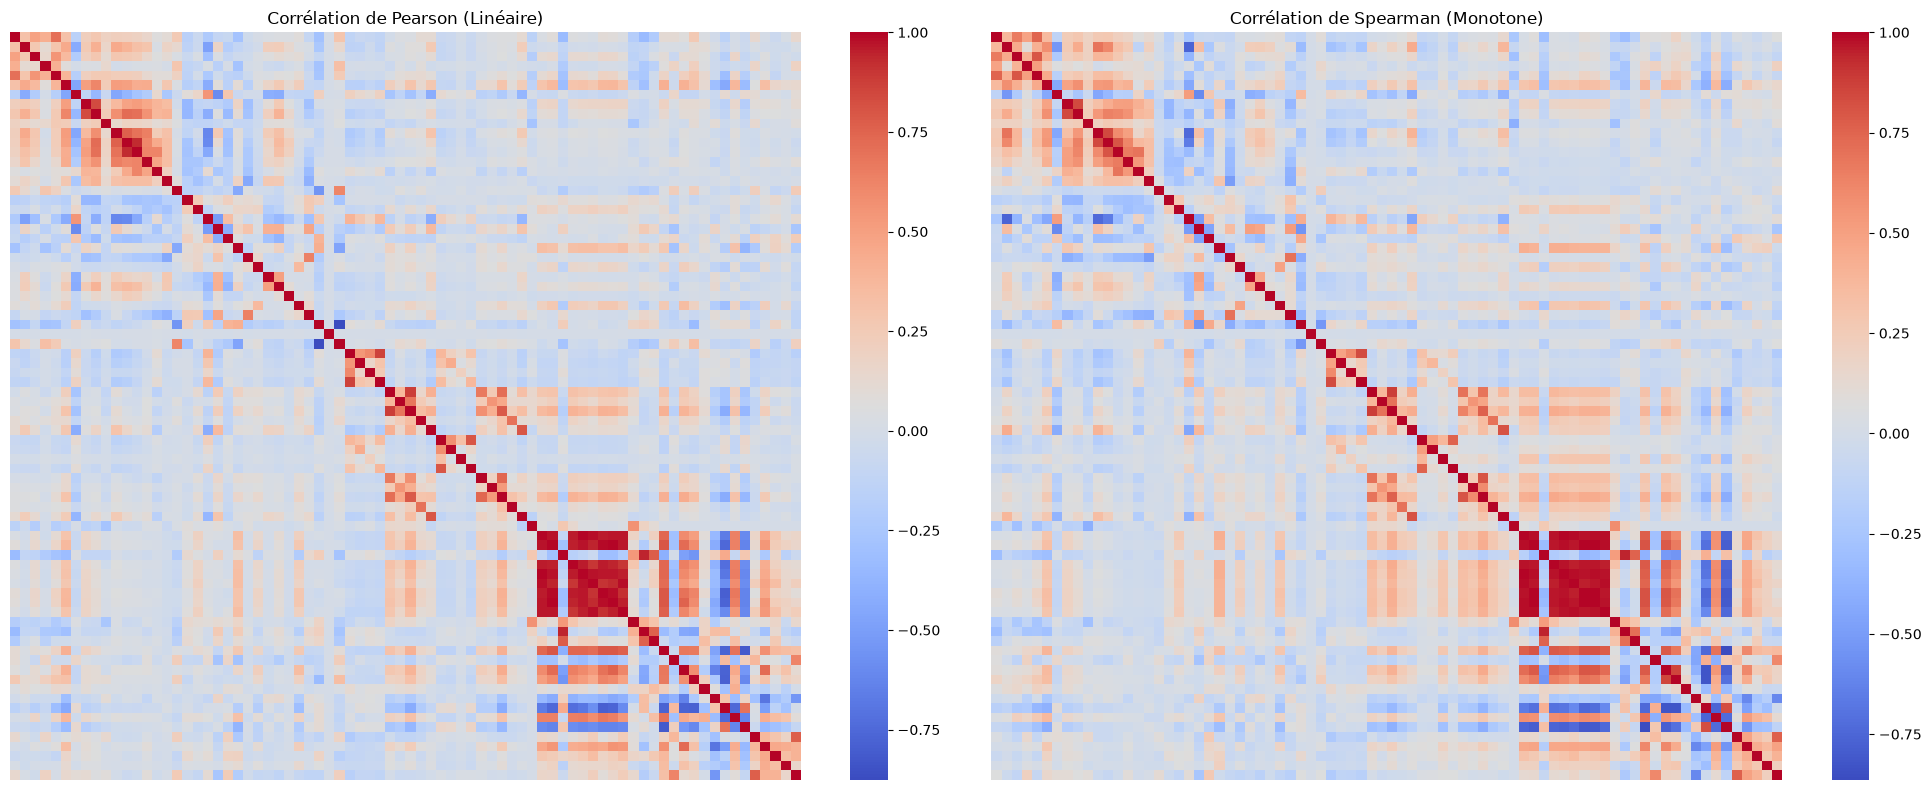

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sélection des variables numériques
numeric_cols = Merge_final_3.select_dtypes(include=['float64', 'int64']).columns

# Calcul des deux matrices
corr_pearson = Merge_final_3[numeric_cols].corr(method='pearson')
corr_spearman = Merge_final_3[numeric_cols].corr(method='spearman')

# Affichage côte à côte
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Heatmap Pearson
sns.heatmap(corr_pearson, annot=False, cmap='coolwarm', ax=axes[0])
axes[0].set_title('Corrélation de Pearson (Linéaire)')

axes[0].set_xticks([])
axes[0].set_yticks([])

# Heatmap Spearman
sns.heatmap(corr_spearman, annot=False, cmap='coolwarm', ax=axes[1])
axes[1].set_title('Corrélation de Spearman (Monotone)')

axes[1].set_xticks([])
axes[1].set_yticks([])


plt.tight_layout()
plt.show()